# Análisis extra — Transfermarkt

Tres preguntas que cruzan varias tablas Silver y Gold:
1. ¿Hubo inflación en el mercado de pases?
2. ¿Al jugador le conviene ser transferido?
3. ¿El club que más gasta es el que sale campeón?

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

S = "workspace.tp_transfermarkt"
spark.sql(f"USE {S}")

BIG5 = "('GB1', 'ES1', 'IT1', 'L1', 'FR1')"
ULTIMA = 2025   # última temporada completa (2025/26)

# Transferencias entre dos clubes distintos, con la temporada a la que pertenecen.
# Junio en adelante cuenta para la temporada que empieza ese año; enero a mayo, para la anterior.
spark.sql("""
CREATE OR REPLACE TEMP VIEW tr AS
SELECT *,
       CASE WHEN month(transfer_date) >= 6 THEN year(transfer_date)
            ELSE year(transfer_date) - 1 END AS temporada
FROM silver_transfers
WHERE from_club_id IS NOT NULL AND to_club_id IS NOT NULL
  AND from_club_id <> to_club_id
""")
display(spark.sql("SELECT min(temporada) AS desde, max(temporada) AS hasta, count(*) AS movimientos FROM tr"))

desde,hasta,movimientos
1993,2030,175157


## 1. ¿Hubo inflación en el mercado de pases?

Monto total, promedio y mediana de las transferencias pagas por temporada, y el promedio de las 10 más caras de cada año.
La mediana sirve para ver si sube todo el mercado o solo los pases grandes.

In [0]:
inflacion = spark.sql(f"""
WITH top10 AS (
  SELECT temporada, avg(transfer_fee) AS prom_top10 FROM (
    SELECT temporada, transfer_fee,
           row_number() OVER (PARTITION BY temporada ORDER BY transfer_fee DESC) AS rn
    FROM tr WHERE transfer_fee > 0) WHERE rn <= 10
  GROUP BY temporada)
SELECT t.temporada,
       count(*) AS movimientos,
       count_if(t.transfer_fee > 0) AS transferencias_pagas,
       round(sum(t.transfer_fee) / 1e6, 1) AS total_millones,
       round(avg(CASE WHEN t.transfer_fee > 0 THEN t.transfer_fee END) / 1e6, 2) AS promedio_millones,
       round(percentile_approx(CASE WHEN t.transfer_fee > 0 THEN t.transfer_fee END, 0.5) / 1e6, 2) AS mediana_millones,
       round(max(t.transfer_fee) / 1e6, 1) AS maximo_millones,
       round(max(x.prom_top10) / 1e6, 1) AS promedio_top10_millones
FROM tr t LEFT JOIN top10 x ON x.temporada = t.temporada
WHERE t.temporada BETWEEN 2012 AND {ULTIMA}
GROUP BY t.temporada ORDER BY t.temporada
""")
display(inflacion)

temporada,movimientos,transferencias_pagas,total_millones,promedio_millones,mediana_millones,maximo_millones,promedio_top10_millones
2012,3992,281,1003.2,3.57,1.25,42.0,30.7
2013,4919,371,1765.5,4.76,1.25,88.0,44.9
2014,6049,461,1971.4,4.28,1.5,81.7,51.3
2015,7211,618,2828.0,4.58,1.63,76.0,51.1
2016,8366,741,3751.8,5.06,1.75,105.0,51.9
2017,9975,938,5432.9,5.79,1.6,222.0,98.0
2018,11544,1115,5711.4,5.12,1.7,180.0,82.9
2019,12606,1310,7660.5,5.85,1.8,127.2,87.5
2020,13597,1095,4809.0,4.39,1.16,100.0,64.3
2021,14915,1346,5302.0,3.94,1.2,117.5,71.6


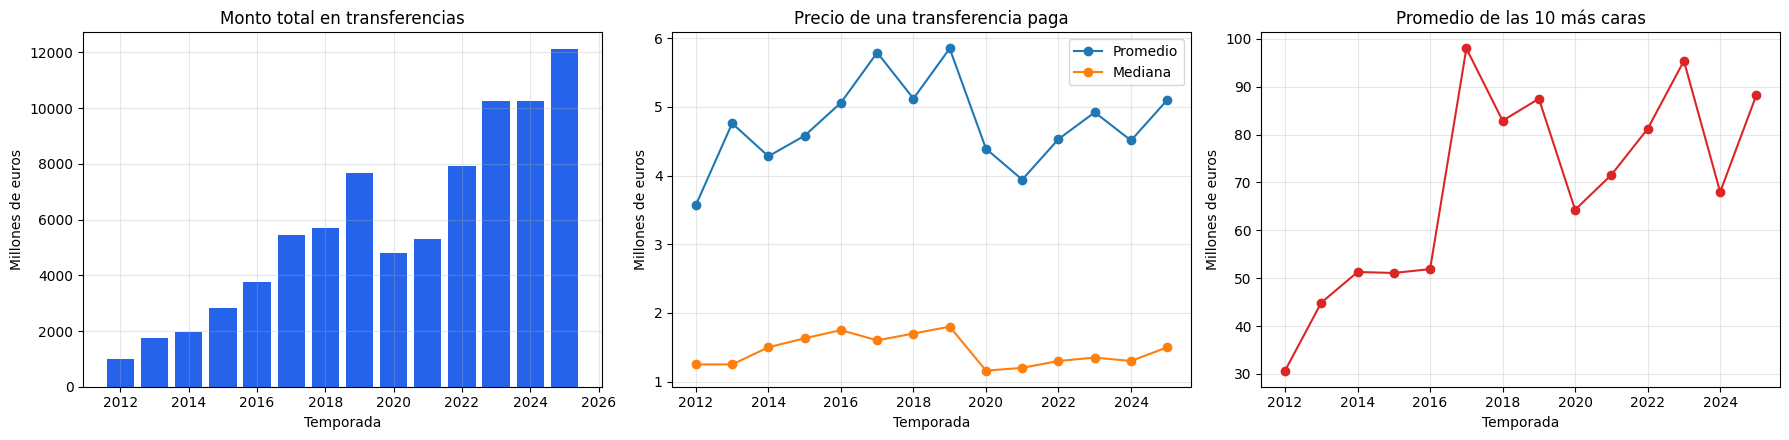

Promedio 2012-2014 contra las últimas 3 temporadas:
total_millones: 1580.03 -> 10879.90  (+589%)
promedio_millones: 4.20 -> 4.84  (+15%)
mediana_millones: 1.33 -> 1.38  (+4%)
promedio_top10_millones: 42.30 -> 83.90  (+98%)


In [0]:
pdf = inflacion.toPandas()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

ax[0].bar(pdf["temporada"], pdf["total_millones"], color="#2563eb")
ax[0].set_title("Monto total en transferencias")
ax[0].set_ylabel("Millones de euros")

ax[1].plot(pdf["temporada"], pdf["promedio_millones"], marker="o", label="Promedio")
ax[1].plot(pdf["temporada"], pdf["mediana_millones"], marker="o", label="Mediana")
ax[1].set_title("Precio de una transferencia paga")
ax[1].set_ylabel("Millones de euros")
ax[1].legend()

ax[2].plot(pdf["temporada"], pdf["promedio_top10_millones"], marker="o", color="#dc2626")
ax[2].set_title("Promedio de las 10 más caras")
ax[2].set_ylabel("Millones de euros")

for a in ax:
    a.set_xlabel("Temporada")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

def crecimiento(col):
    ini = pdf[pdf["temporada"].between(2012, 2014)][col].mean()
    fin = pdf[pdf["temporada"].between(ULTIMA - 2, ULTIMA)][col].mean()
    print(f"{col}: {ini:.2f} -> {fin:.2f}  ({(fin / ini - 1) * 100:+.0f}%)")

print("Promedio 2012-2014 contra las últimas 3 temporadas:")
for c in ["total_millones", "promedio_millones", "mediana_millones", "promedio_top10_millones"]:
    crecimiento(c)

Además de lo que se paga, se mira cómo se mueve el valor de mercado: el valor promedio de los jugadores de las 5 grandes ligas y el de los 100 más valiosos de cada temporada (última valuación de cada jugador en la temporada).

temporada,valor_medio_big5_millones,valor_medio_top100_millones
2012,2.85,33.3
2013,2.77,34.2
2014,2.76,37.5
2015,2.84,41.5
2016,3.01,45.1
2017,4.16,70.1
2018,4.91,77.5
2019,4.29,65.0
2020,4.34,66.2
2021,4.23,65.1


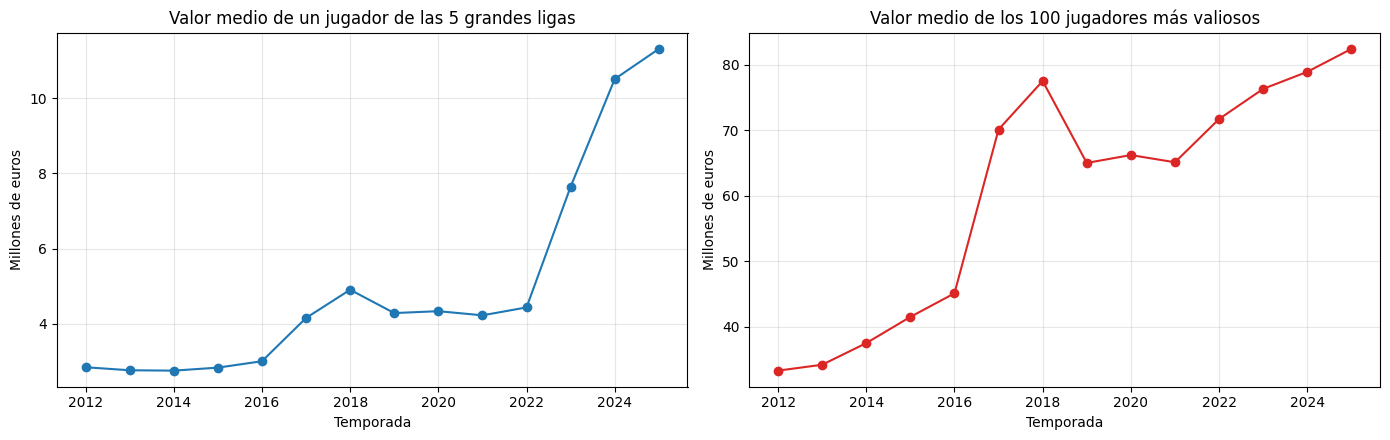

In [0]:
valores = spark.sql(f"""
WITH v AS (
  SELECT player_id, market_value_in_eur AS valor,
         player_club_domestic_competition_id AS liga,
         CASE WHEN month(date) >= 7 THEN year(date) ELSE year(date) - 1 END AS temporada,
         date
  FROM silver_player_valuations),
u AS (
  SELECT * FROM (
    SELECT *, row_number() OVER (PARTITION BY player_id, temporada ORDER BY date DESC) AS rn FROM v)
  WHERE rn = 1 AND temporada BETWEEN 2012 AND {ULTIMA}),
r AS (SELECT *, row_number() OVER (PARTITION BY temporada ORDER BY valor DESC) AS puesto FROM u)
SELECT temporada,
       round(avg(CASE WHEN liga IN {BIG5} THEN valor END) / 1e6, 2) AS valor_medio_big5_millones,
       round(avg(CASE WHEN puesto <= 100 THEN valor END) / 1e6, 1) AS valor_medio_top100_millones
FROM r GROUP BY temporada ORDER BY temporada
""")
display(valores)

pv = valores.toPandas()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(pv["temporada"], pv["valor_medio_big5_millones"], marker="o")
ax[0].set_title("Valor medio de un jugador de las 5 grandes ligas")
ax[1].plot(pv["temporada"], pv["valor_medio_top100_millones"], marker="o", color="#dc2626")
ax[1].set_title("Valor medio de los 100 jugadores más valiosos")
for a in ax:
    a.set_xlabel("Temporada")
    a.set_ylabel("Millones de euros")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. ¿Al jugador le conviene ser transferido?

Se comparan pares de temporadas consecutivas del mismo jugador (antes y después) entre los que jugaron al menos 900 minutos en la temporada anterior.
Los que se fueron en el mercado de verano (junio a septiembre) se separan de los que se quedaron en su club, que sirven como grupo de control.

Se mide:
- si mantuvo o subió sus minutos
- goles + asistencias cada 90 minutos (solo para los que también jugaron 900 minutos después)
- la mediana del cambio de valor de mercado

Limitación: si el jugador se fue a una liga que el dataset no sigue, no aparece en la temporada siguiente y queda afuera.

In [0]:
efecto = spark.sql(f"""
WITH st AS (
  SELECT player_id, season, minutos, (goles + asistencias) * 90 / minutos AS ga90
  FROM gold_player_season_stats WHERE minutos > 0),
pares AS (
  SELECT a.player_id, b.season AS temporada,
         a.minutos AS min_antes, b.minutos AS min_despues,
         a.ga90 AS ga90_antes, b.ga90 AS ga90_despues
  FROM st a JOIN st b ON a.player_id = b.player_id AND b.season = a.season + 1
  WHERE a.minutos >= 900 AND b.season <= {ULTIMA}),
mov AS (
  SELECT player_id, year(transfer_date) AS temporada,
         max(transfer_fee) AS fee,
         min_by(from_club_id, transfer_date) AS from_club_id,
         max_by(to_club_id, transfer_date) AS to_club_id
  FROM tr WHERE month(transfer_date) BETWEEN 6 AND 9
  GROUP BY player_id, year(transfer_date)),
uv AS (
  SELECT player_id, temporada, valor FROM (
    SELECT player_id, market_value_in_eur AS valor,
           CASE WHEN month(date) >= 7 THEN year(date) ELSE year(date) - 1 END AS temporada,
           row_number() OVER (
             PARTITION BY player_id, CASE WHEN month(date) >= 7 THEN year(date) ELSE year(date) - 1 END
             ORDER BY date DESC) AS rn
    FROM silver_player_valuations)
  WHERE rn = 1)
SELECT p.*, pl.position, p.temporada - year(pl.date_of_birth) AS edad,
       m.fee,
       CASE WHEN m.player_id IS NULL THEN 'No transferido'
            WHEN m.fee > 0 THEN 'Transferido con pago'
            ELSE 'Libre, préstamo o sin dato' END AS grupo,
       CASE WHEN m.player_id IS NULL THEN NULL
            WHEN c0.domestic_competition_id IN {BIG5} AND c1.domestic_competition_id IN {BIG5} THEN 'Entre ligas grandes'
            WHEN c1.domestic_competition_id IN {BIG5} THEN 'Sube a una liga grande'
            WHEN c0.domestic_competition_id IN {BIG5} THEN 'Baja de una liga grande'
            ELSE 'Entre ligas menores' END AS direccion,
       v0.valor AS valor_antes, v1.valor AS valor_despues
FROM pares p
LEFT JOIN silver_players pl ON pl.player_id = p.player_id
LEFT JOIN mov m ON m.player_id = p.player_id AND m.temporada = p.temporada
LEFT JOIN silver_clubs c0 ON c0.club_id = m.from_club_id
LEFT JOIN silver_clubs c1 ON c1.club_id = m.to_club_id
LEFT JOIN uv v0 ON v0.player_id = p.player_id AND v0.temporada = p.temporada - 1
LEFT JOIN uv v1 ON v1.player_id = p.player_id AND v1.temporada = p.temporada
""")
efecto.createOrReplaceTempView("efecto")

METRICAS = """
  count(*) AS jugadores,
  round(avg(edad), 1) AS edad_promedio,
  round(avg(min_antes)) AS minutos_antes,
  round(avg(min_despues)) AS minutos_despues,
  round(100 * avg(CASE WHEN min_despues >= min_antes THEN 1 ELSE 0 END), 1) AS pct_mantiene_o_sube_minutos,
  round(avg(CASE WHEN min_despues >= 900 THEN ga90_antes END), 3) AS ga90_antes,
  round(avg(CASE WHEN min_despues >= 900 THEN ga90_despues END), 3) AS ga90_despues,
  round(100 * percentile_approx(valor_despues / valor_antes - 1, 0.5), 1) AS mediana_cambio_valor_pct
"""
por_grupo = spark.sql(f"SELECT grupo, {METRICAS} FROM efecto GROUP BY grupo ORDER BY jugadores DESC")
display(por_grupo)

grupo,jugadores,edad_promedio,minutos_antes,minutos_despues,pct_mantiene_o_sube_minutos,ga90_antes,ga90_despues,mediana_cambio_valor_pct
No transferido,33873,27.3,2174.0,1900.0,38.8,0.234,0.226,-10.0
"Libre, préstamo o sin dato",4185,26.3,1877.0,1535.0,37.4,0.222,0.228,-14.3
Transferido con pago,3639,24.9,2319.0,1944.0,37.5,0.299,0.283,0.0


Mismo análisis solo para los transferidos, según hacia dónde se movieron (las 5 grandes ligas contra el resto).

direccion,jugadores,edad_promedio,minutos_antes,minutos_despues,pct_mantiene_o_sube_minutos,ga90_antes,ga90_despues,mediana_cambio_valor_pct
Entre ligas grandes,3308,25.6,2198.0,1957.0,41.3,0.261,0.258,0.0
Entre ligas menores,3100,25.9,1919.0,1517.0,35.6,0.25,0.249,0.0
Sube a una liga grande,858,24.2,2360.0,1633.0,26.6,0.321,0.236,10.0
Baja de una liga grande,558,27.1,1876.0,1655.0,41.6,0.218,0.302,-20.0


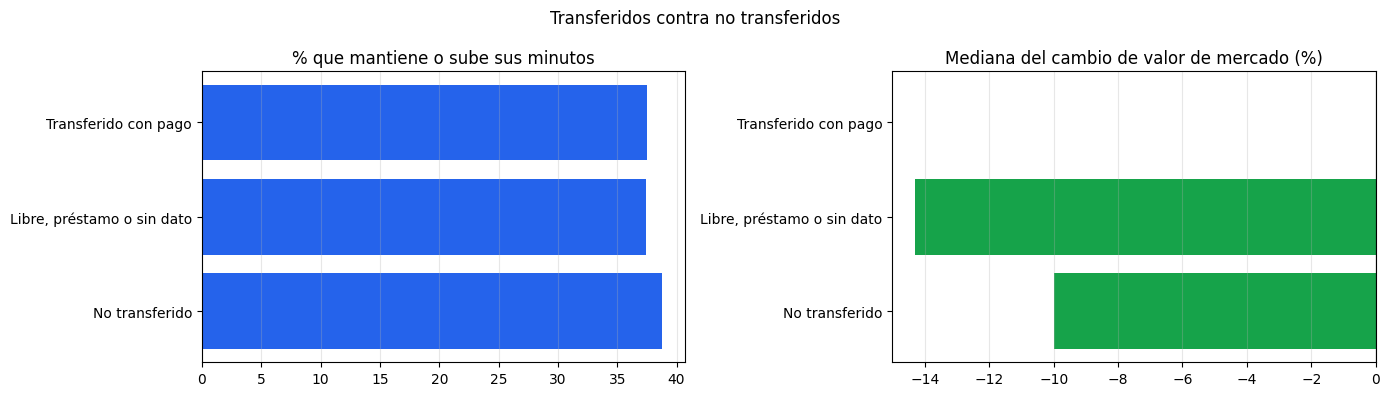

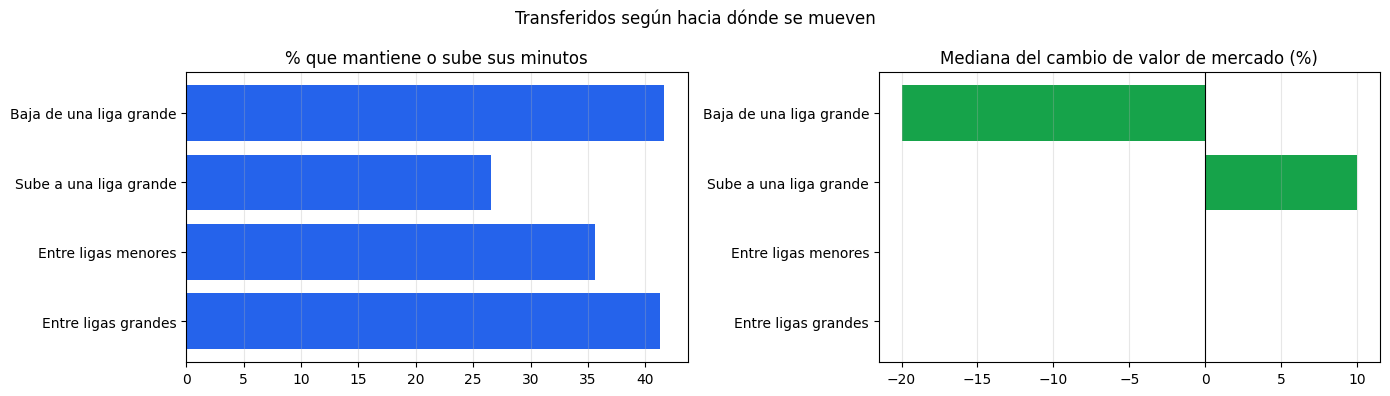

In [0]:
por_direccion = spark.sql(f"""
SELECT direccion, {METRICAS} FROM efecto
WHERE grupo <> 'No transferido'
GROUP BY direccion ORDER BY jugadores DESC
""")
display(por_direccion)

def barras(df, col_cat, titulo):
    p = df.toPandas()
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].barh(p[col_cat], p["pct_mantiene_o_sube_minutos"], color="#2563eb")
    ax[0].set_title("% que mantiene o sube sus minutos")
    ax[1].barh(p[col_cat], p["mediana_cambio_valor_pct"], color="#16a34a")
    ax[1].axvline(0, color="black", linewidth=0.8)
    ax[1].set_title("Mediana del cambio de valor de mercado (%)")
    for a in ax:
        a.grid(axis="x", alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

barras(por_grupo, "grupo", "Transferidos contra no transferidos")
barras(por_direccion, "direccion", "Transferidos según hacia dónde se mueven")

## 3. ¿El club que más gasta es el que sale campeón?

El dataset no tiene una tabla de títulos, así que la tabla de posiciones de cada liga se arma a partir de los partidos (3 puntos por victoria, 1 por empate, desempate por diferencia de gol).
Solo se usan las 5 grandes ligas y las temporadas completas. No se tienen en cuenta las quitas de puntos por sanciones.

El gasto se mide de dos formas: lo que el club pagó en esa temporada y lo que pagó en las últimas 3, porque un plantel se arma en varios mercados.

In [0]:
spark.sql(f"""
CREATE OR REPLACE TEMP VIEW posiciones AS
WITH pc AS (
  SELECT competition_id, season, home_club_id AS club_id, home_club_goals AS gf, away_club_goals AS gc
  FROM silver_games WHERE competition_id IN {BIG5}
  UNION ALL
  SELECT competition_id, season, away_club_id, away_club_goals, home_club_goals
  FROM silver_games WHERE competition_id IN {BIG5}),
tabla AS (
  SELECT competition_id, season, club_id, count(*) AS pj,
         sum(CASE WHEN gf > gc THEN 3 WHEN gf = gc THEN 1 ELSE 0 END) AS puntos,
         sum(gf - gc) AS dif_gol
  FROM pc WHERE club_id IS NOT NULL
  GROUP BY competition_id, season, club_id),
completas AS (
  SELECT competition_id, season FROM tabla
  GROUP BY competition_id, season
  HAVING min(pj) = max(pj) AND max(pj) = 2 * (count(*) - 1)),
pos AS (
  SELECT t.*,
         row_number() OVER (PARTITION BY t.competition_id, t.season ORDER BY t.puntos DESC, t.dif_gol DESC) AS posicion
  FROM tabla t
  JOIN completas c ON c.competition_id = t.competition_id AND c.season = t.season),
gasto AS (
  SELECT p.competition_id, p.season, p.club_id,
         coalesce(sum(CASE WHEN x.temporada = p.season THEN x.transfer_fee END), 0) AS gasto,
         coalesce(sum(x.transfer_fee), 0) AS gasto_3
  FROM pos p
  LEFT JOIN tr x ON x.to_club_id = p.club_id AND x.temporada BETWEEN p.season - 2 AND p.season
  GROUP BY p.competition_id, p.season, p.club_id)
SELECT p.competition_id, p.season, p.club_id, cl.name AS club_name,
       p.pj, p.puntos, p.dif_gol, p.posicion, g.gasto, g.gasto_3,
       rank() OVER (PARTITION BY p.competition_id, p.season ORDER BY g.gasto DESC) AS rank_gasto,
       rank() OVER (PARTITION BY p.competition_id, p.season ORDER BY g.gasto_3 DESC) AS rank_gasto_3
FROM pos p
JOIN gasto g ON g.competition_id = p.competition_id AND g.season = p.season AND g.club_id = p.club_id
LEFT JOIN silver_clubs cl ON cl.club_id = p.club_id
WHERE p.season BETWEEN 2014 AND {ULTIMA}
""")

campeones = spark.sql("""
SELECT competition_id AS liga, season AS temporada, club_name AS campeon, puntos,
       round(gasto / 1e6, 1) AS gasto_temporada_millones, rank_gasto AS puesto_en_gasto,
       round(gasto_3 / 1e6, 1) AS gasto_3_temporadas_millones, rank_gasto_3 AS puesto_en_gasto_3
FROM posiciones WHERE posicion = 1
ORDER BY liga, temporada
""")
display(campeones)

liga,temporada,campeon,puntos,gasto_temporada_millones,puesto_en_gasto,gasto_3_temporadas_millones,puesto_en_gasto_3
ES1,2014,FC Barcelona,94,123.7,1,211.7,1
ES1,2015,FC Barcelona,91,0.0,16,211.7,2
ES1,2016,Real Madrid,93,30.0,4,247.4,1
ES1,2017,FC Barcelona,93,348.1,1,442.9,1
ES1,2018,FC Barcelona,87,138.9,2,581.8,1
ES1,2019,Real Madrid,87,238.5,3,443.8,2
ES1,2020,Atlético de Madrid,86,90.5,2,472.9,2
ES1,2021,Real Madrid,86,31.0,5,269.5,4
ES1,2022,FC Barcelona,88,159.0,1,339.9,1
ES1,2023,Real Madrid,95,160.0,1,271.0,1


Resumen: qué porcentaje de los campeones fue el que más gastó de su liga, y correlación entre el puesto en gasto y la posición final.
La correlación se calcula sobre los puestos (correlación de Spearman): 1 sería que el orden de gasto y el de la tabla coinciden siempre, 0 que no tienen relación.

In [0]:
resumen = spark.sql("""
SELECT count(*) AS campeonatos,
       round(100 * avg(CASE WHEN rank_gasto = 1 THEN 1 ELSE 0 END), 1) AS pct_mas_gasto_temporada,
       round(100 * avg(CASE WHEN rank_gasto <= 3 THEN 1 ELSE 0 END), 1) AS pct_top3_gasto_temporada,
       round(100 * avg(CASE WHEN rank_gasto_3 = 1 THEN 1 ELSE 0 END), 1) AS pct_mas_gasto_3,
       round(100 * avg(CASE WHEN rank_gasto_3 <= 3 THEN 1 ELSE 0 END), 1) AS pct_top3_gasto_3
FROM posiciones WHERE posicion = 1
""")
display(resumen)

correlacion = spark.sql("""
SELECT competition_id AS liga,
       round(corr(rank_gasto, posicion), 2) AS corr_gasto_temporada,
       round(corr(rank_gasto_3, posicion), 2) AS corr_gasto_3_temporadas
FROM posiciones GROUP BY competition_id
UNION ALL
SELECT 'TOTAL', round(corr(rank_gasto, posicion), 2), round(corr(rank_gasto_3, posicion), 2)
FROM posiciones
""")
display(correlacion)

campeonatos,pct_mas_gasto_temporada,pct_top3_gasto_temporada,pct_mas_gasto_3,pct_top3_gasto_3
59,35.6,67.8,42.4,76.3


liga,corr_gasto_temporada,corr_gasto_3_temporadas
ES1,0.56,0.66
GB1,0.48,0.68
L1,0.57,0.63
FR1,0.67,0.69
IT1,0.68,0.8
TOTAL,0.59,0.7


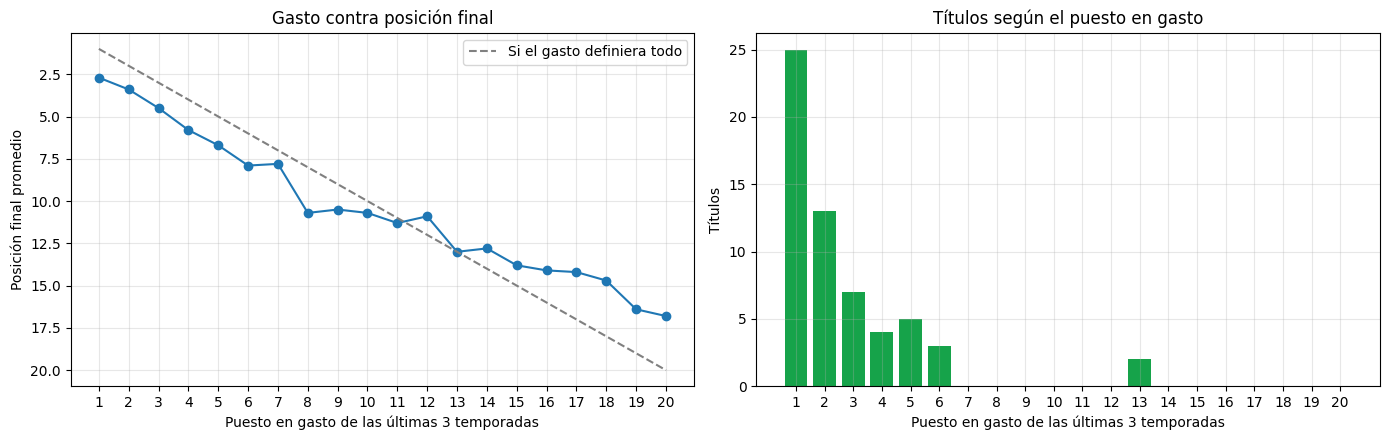

club_name,liga,titulos,gasto_total_millones,puesto_promedio_en_gasto
Bayern Munich,L1,11,1029.0,3.0
Paris Saint-Germain,FR1,9,1771.0,2.0
FC Barcelona,ES1,7,1477.0,3.0
Manchester City,GB1,6,2278.0,4.0
Juventus FC,IT1,6,1578.0,2.0
Real Madrid,ES1,4,1179.0,4.0
Inter Milan,IT1,3,996.0,6.0
Chelsea FC,GB1,2,2753.0,4.0
Liverpool FC,GB1,2,1637.0,8.0
SSC Napoli,IT1,2,1020.0,4.0


In [0]:
pp = spark.sql("""
SELECT rank_gasto_3 AS puesto_gasto, round(avg(posicion), 1) AS posicion_promedio,
       count_if(posicion = 1) AS titulos
FROM posiciones WHERE rank_gasto_3 <= 20
GROUP BY rank_gasto_3 ORDER BY rank_gasto_3
""").toPandas()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(pp["puesto_gasto"], pp["posicion_promedio"], marker="o")
ax[0].plot([1, 20], [1, 20], linestyle="--", color="gray", label="Si el gasto definiera todo")
ax[0].invert_yaxis()
ax[0].set_xlabel("Puesto en gasto de las últimas 3 temporadas")
ax[0].set_ylabel("Posición final promedio")
ax[0].set_title("Gasto contra posición final")
ax[0].legend()
ax[1].bar(pp["puesto_gasto"], pp["titulos"], color="#16a34a")
ax[1].set_xlabel("Puesto en gasto de las últimas 3 temporadas")
ax[1].set_ylabel("Títulos")
ax[1].set_title("Títulos según el puesto en gasto")
for a in ax:
    a.set_xticks(range(1, 21))
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

titulos_club = spark.sql("""
SELECT club_name, competition_id AS liga,
       count_if(posicion = 1) AS titulos,
       round(sum(gasto) / 1e6) AS gasto_total_millones,
       round(avg(rank_gasto)) AS puesto_promedio_en_gasto
FROM posiciones GROUP BY club_name, competition_id
HAVING count_if(posicion = 1) > 0
ORDER BY titulos DESC, gasto_total_millones DESC
""")
display(titulos_club)

In [0]:
display(correlacion)

liga,corr_gasto_temporada,corr_gasto_3_temporadas
ES1,0.56,0.66
GB1,0.48,0.68
L1,0.57,0.63
FR1,0.67,0.69
IT1,0.68,0.8
TOTAL,0.59,0.7
